# Desenvolvimento do modelo de Multi Layer Perceptron (MLP) Classifier Binário de quatro camadas ocultas
---

***A Fazeres:***
- Criar um limiar para o modelo dizer se é ou não ataque, com predict. EX.: se der 40% de chance de ser ataque, dizer que tem uma grande probabilidade de ser ataque

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.neural_network import MLPClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Buscando em: {caminho_predexan}")
print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Buscando em: C:\Users\rmaca\PUC_eixo7\projeto\pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1\src
Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')
# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')
# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento do Modelo de MLP de Classificação
---

### 1. Treino do modelo
---

#### 1.1. Instanciando a classe MLPClassifier
---

In [8]:
modelo = MLPClassifier(hidden_layer_sizes=(256, 128, 64, 32), max_iter=2000, tol=0.0001, learning_rate_init=0.001, alpha=0.1, learning_rate='adaptive', validation_fraction=0.1, n_iter_no_change=15, solver="adam", activation='relu', verbose=True, random_state=42)

**Explicando os parâmetros utilizados em MLPClassifier:**

#### 1.2. Treino do modelo
---

Para o treino do modelo, é usada a expressão `modelo.fit(X_treino, y_treino)`. Será rodado em conjunto com a função `imprimir_tempo()` do módulo `metricas` do pacote `Predexan`, para poder ter o tempo de processamento registrado: 

In [9]:
pm.imprimir_desempenho(modelo.fit,X_treino, y_treino)

Iteration 1, loss = 0.40163039
Iteration 2, loss = 0.29931595
Iteration 3, loss = 0.27332046
Iteration 4, loss = 0.26321627
Iteration 5, loss = 0.25498595
Iteration 6, loss = 0.24963956
Iteration 7, loss = 0.24047582
Iteration 8, loss = 0.24361052
Iteration 9, loss = 0.23289757
Iteration 10, loss = 0.22926636
Iteration 11, loss = 0.22670839
Iteration 12, loss = 0.22073176
Iteration 13, loss = 0.21715587
Iteration 14, loss = 0.22126148
Iteration 15, loss = 0.21507783
Iteration 16, loss = 0.21028951
Iteration 17, loss = 0.21005178
Iteration 18, loss = 0.20765218
Iteration 19, loss = 0.20663924
Iteration 20, loss = 0.20470781
Iteration 21, loss = 0.20364969
Iteration 22, loss = 0.20179736
Iteration 23, loss = 0.20125058
Iteration 24, loss = 0.20129254
Iteration 25, loss = 0.20055169
Iteration 26, loss = 0.20033056
Iteration 27, loss = 0.20106582
Iteration 28, loss = 0.19983991
Iteration 29, loss = 0.19965599
Iteration 30, loss = 0.20092552
Iteration 31, loss = 0.19881157
Iteration 32, los

MLPClassifier(alpha=0.1, hidden_layer_sizes=(256, 128, 64, 32),
              learning_rate='adaptive', max_iter=2000, n_iter_no_change=15,
              random_state=42, verbose=True)

### 2. Realização de predições com os dados de teste
---

Para a predição probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo.predict_proba(X_teste)`. Para a predição binária, é expresso da mesma forma, mas com o uso do método `predict()`. Ambas terão seu desempenho medido pela função `imprimir_desempenho()` de `Predexan`.

#### 2.1. Predição Probababilística
---

In [57]:
y_predicao_probabilistica = pm.imprimir_desempenho(modelo.predict_proba, X_teste)[:,1]


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 23/05/2026 17:09:52

1. TEMPO: 1.7792s (0.03 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 164.32 MB
   - Diferença líquida de RAM no processo: 2.61 MB
   - Total RAM alocada para o processo: 417.47 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 68.3%

Execução concluída em: 23/05/2026 17:09:54



#### 2.2. Predição Binária
---

Para a Predição Binária, é usado o método `predict()` na seguinte expressão: `modelo.predict(X_teste)`

In [58]:
y_predicao_binaria = pm.imprimir_desempenho(modelo.predict, X_teste)


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 23/05/2026 17:09:54

1. TEMPO: 1.6491s (0.03 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 164.32 MB
   - Diferença líquida de RAM no processo: 0.00 MB
   - Total RAM alocada para o processo: 417.47 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 77.3%

Execução concluída em: 23/05/2026 17:09:56



In [59]:
type(y_predicao_binaria)

numpy.ndarray

### 3. Desempenho do modelo
---

O modelo possui métricas de desempenho baseadas nos resultados dos testes, sendo essas: 

- `Pontuação` que traz a `Acurácia Geral`.
- `Matriz de Confusão`:  permite a visualização do desempenho do modelo, uma vez que mostra o total de predições Verdadeiras Positivas (TP), Verdadeiras Negativa (TN), Falsas Positivas (FP) e Falsas Negativas (FN). No contexto do projeto, que visa a probailidade de detecção de ameaças, os alvos são sempre atingir ao máximoTN e TP, mas FN é o erro crítico, pois pode levar ao usuário da aplicação a ignorar a hipótese do ataque em sua máquina, podendo propiciar uma piora no caso, já que este pode deixar de buscar ajuda e manutenções e FP é o alarme falso.
- `Relatório de Classificação` que traz cálculos como `Precision`, `Recall` e `F1-Score`.
- `Curva ROC AUC` que traz uma visualização gráfica.
- `Curva Precision-Recall`

Serão feitos testes com limiares para se determinar qual deles tem melhor desempenho, revocação e precisão. As seguintes sub-seções trarão as métricas e gráficos de forma individual para cada teste.

#### 3.1. Limiar Não Customizado
---

##### 3.1.1. Matriz de Confusão
---

<Axes: >

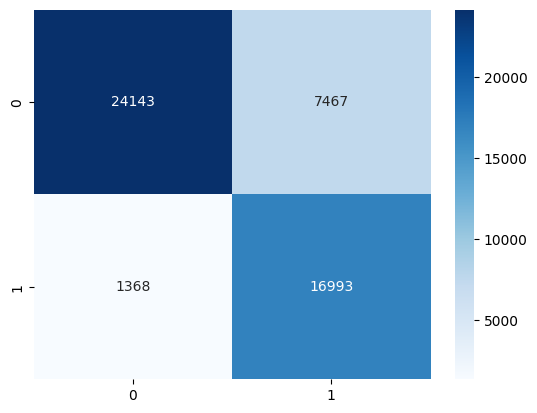

In [60]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues')

In [14]:
(tn, fp), (fn, tp) = matriz_confusao
total = (tn+fn+tp+fp)

In [15]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 24143 casos que o modelo apontou como resultado negativo, corretamente. Representa 48.31% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 1368 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 2.74% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 16993 casos em que o modelo apontou como resultado positivo, corretamente. Representa 34.01% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 7467 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 14.94% do total de predições 

##### 3.1.2. Relatório de Classificação
---

In [16]:
relatorio_classificacao = classification_report(y_teste, y_predicao_binaria)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.95      0.76      0.85     31610
         1.0       0.69      0.93      0.79     18361

    accuracy                           0.82     49971
   macro avg       0.82      0.84      0.82     49971
weighted avg       0.85      0.82      0.83     49971



##### 3.1.3. Curva ROC-AUC
---

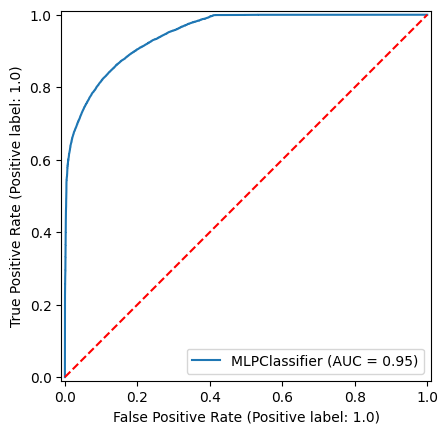

In [17]:
curva = RocCurveDisplay.from_estimator(modelo, X_teste, y_teste)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()

##### 3.1.4. Curva Precision-Recall
---

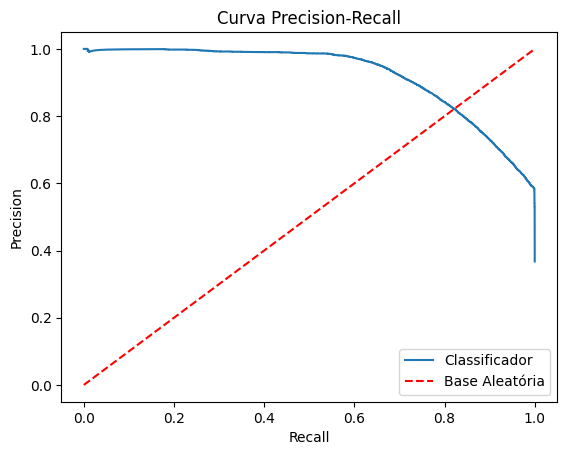

In [77]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica)

#### 3.2. Limiar Customizado
---

In [69]:
y_predicao_probabilistica_customizada = (y_predicao_probabilistica > 0.65).astype(int)

<Axes: >

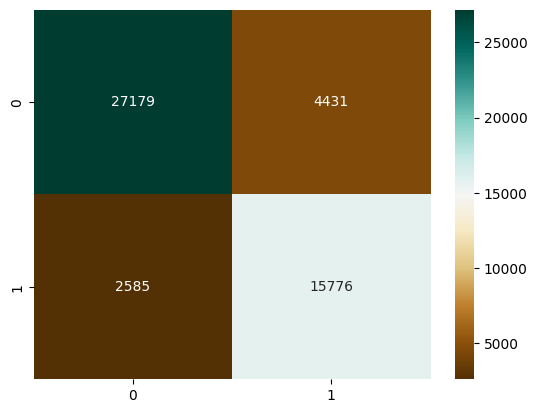

In [70]:
matriz_confusao_customizada = confusion_matrix(y_teste, y_predicao_probabilistica_customizada)
sns.heatmap(matriz_confusao_customizada, annot=True, fmt='d', cmap='BrBG')

In [71]:
(tn, fp), (fn, tp) = matriz_confusao_customizada
total = (tn+fn+tp+fp)

In [72]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 27179 casos que o modelo apontou como resultado negativo, corretamente. Representa 54.39% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 2585 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 5.17% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 15776 casos em que o modelo apontou como resultado positivo, corretamente. Representa 31.57% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 4431 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 8.87% do total de predições d

In [73]:
relatorio_classificacao = classification_report(y_teste, y_predicao_probabilistica_customizada)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.91      0.86      0.89     31610
         1.0       0.78      0.86      0.82     18361

    accuracy                           0.86     49971
   macro avg       0.85      0.86      0.85     49971
weighted avg       0.86      0.86      0.86     49971



#### 3.3. Limiar Teste 5%
---

##### 3.1.3.1. Teste limite de 5%
---


Matriz com corte em 5%:


<Axes: >

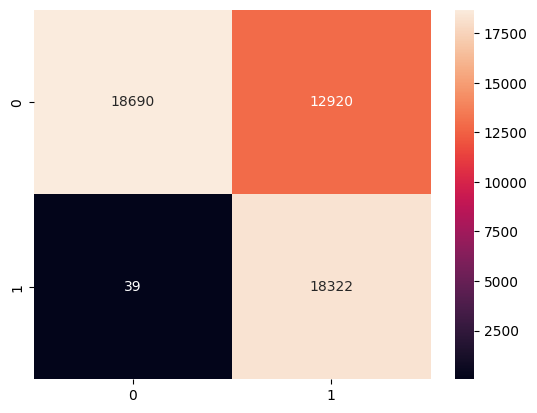

In [26]:
# Teste agressivo 1: Se tiver mais de 5% de chance de ser ataque, já classifica como 1
y_pred_5 = (y_predicao_probabilistica > 0.05).astype(int)
print("\nMatriz com corte em 5%:")
matriz_teste_1 = confusion_matrix(y_teste, y_pred_5)
sns.heatmap(matriz_teste_1, annot=True, fmt='d')

In [27]:
(tn, fp), (fn, tp) = matriz_teste_1
total = (tn+fn+tp+fp)

print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 18690 casos que o modelo apontou como resultado negativo, corretamente. Representa 37.40% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 39 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 0.08% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 18322 casos em que o modelo apontou como resultado positivo, corretamente. Representa 36.67% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 12920 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 25.85% do total de predições d

In [28]:
relatorio_classificacao = classification_report(y_teste, y_pred_5)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       1.00      0.59      0.74     31610
         1.0       0.59      1.00      0.74     18361

    accuracy                           0.74     49971
   macro avg       0.79      0.79      0.74     49971
weighted avg       0.85      0.74      0.74     49971



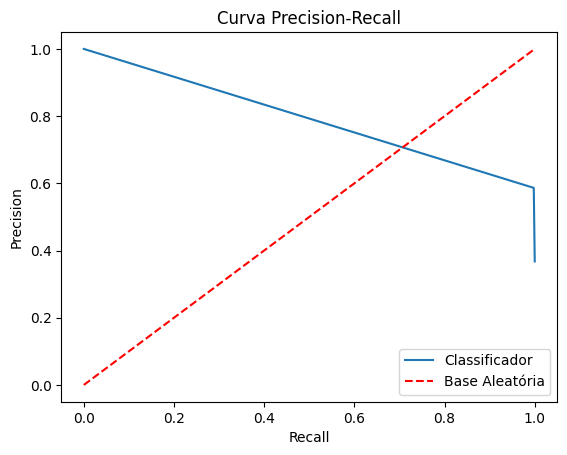

In [29]:
pg.gerar_curva_pr(y_teste, y_pred_5)

#### 3.4. Limiar Teste 10%
---


Matriz com corte em 10%:


<Axes: >

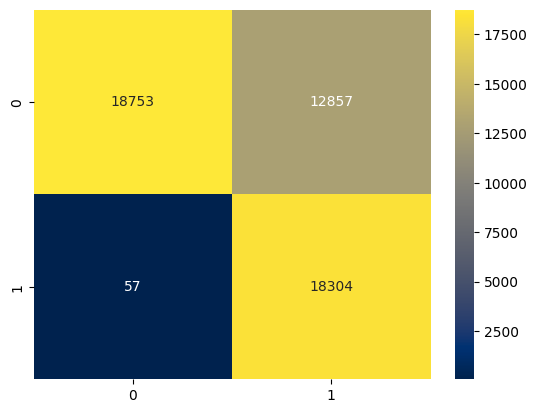

In [30]:
y_pred_10 = (y_predicao_probabilistica > 0.10).astype(int)
print("\nMatriz com corte em 10%:")
matriz_teste_2 = confusion_matrix(y_teste, y_pred_10)
sns.heatmap(matriz_teste_2, annot=True, fmt='d', cmap='cividis')

In [31]:
precision = (tp/(tp+fp))
recall = (tp/(tp+fn))
f1_score = 2*((precision * recall) / (precision + recall))

print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 18690 casos que o modelo apontou como resultado negativo, corretamente. Representa 37.40% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 39 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 0.08% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 18322 casos em que o modelo apontou como resultado positivo, corretamente. Representa 36.67% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 12920 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 25.85% do total de predições d

In [32]:
relatorio_classificacao = classification_report(y_teste, y_pred_10)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       1.00      0.59      0.74     31610
         1.0       0.59      1.00      0.74     18361

    accuracy                           0.74     49971
   macro avg       0.79      0.80      0.74     49971
weighted avg       0.85      0.74      0.74     49971



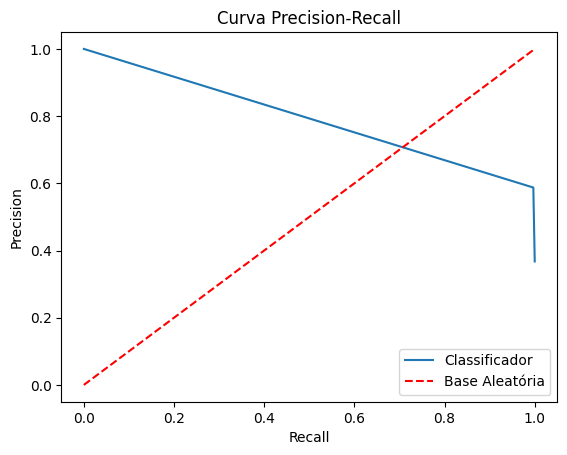

In [33]:
pg.gerar_curva_pr(y_teste, y_pred_10)

#### 3.5. Limiar Teste 15%
---


Matriz com corte em 15%:


<Axes: >

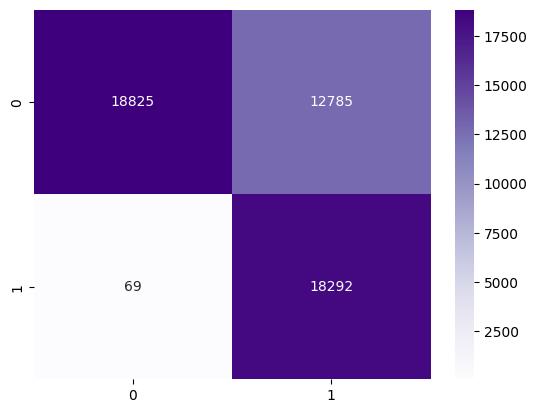

In [34]:
y_pred_15 = (y_predicao_probabilistica > 0.15).astype(int)
print("\nMatriz com corte em 15%:")
matriz_teste_3 = confusion_matrix(y_teste, y_pred_15)
sns.heatmap(matriz_teste_3, annot=True, fmt='d', cmap='Purples')

In [35]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 18690 casos que o modelo apontou como resultado negativo, corretamente. Representa 37.40% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 39 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 0.08% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 18322 casos em que o modelo apontou como resultado positivo, corretamente. Representa 36.67% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 12920 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 25.85% do total de predições d

In [36]:
relatorio_classificacao = classification_report(y_teste, y_pred_15)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       1.00      0.60      0.75     31610
         1.0       0.59      1.00      0.74     18361

    accuracy                           0.74     49971
   macro avg       0.79      0.80      0.74     49971
weighted avg       0.85      0.74      0.74     49971



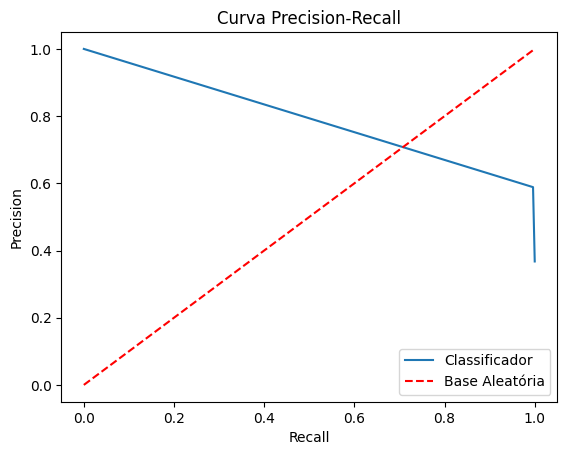

In [37]:
pg.gerar_curva_pr(y_teste, y_pred_15)

#### 3.6. Limiar Teste 20%
---


Matriz com corte em 20%:


<Axes: >

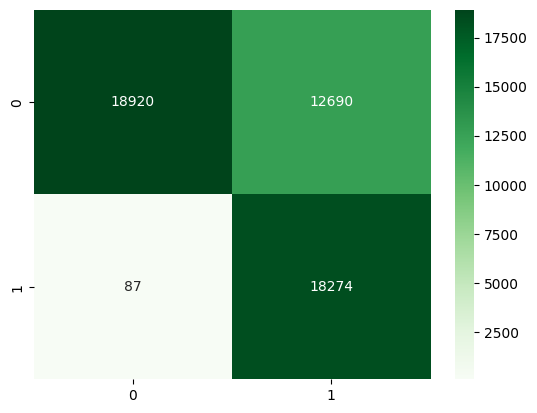

In [38]:
y_pred_20 = (y_predicao_probabilistica > 0.20).astype(int)
print("\nMatriz com corte em 20%:")
matriz_teste_4 = confusion_matrix(y_teste, y_pred_20)
sns.heatmap(matriz_teste_4, annot=True, fmt='d', cmap='Greens')

In [39]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 18690 casos que o modelo apontou como resultado negativo, corretamente. Representa 37.40% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 39 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 0.08% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 18322 casos em que o modelo apontou como resultado positivo, corretamente. Representa 36.67% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 12920 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 25.85% do total de predições d

In [40]:
relatorio_classificacao = classification_report(y_teste, y_pred_20)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       1.00      0.60      0.75     31610
         1.0       0.59      1.00      0.74     18361

    accuracy                           0.74     49971
   macro avg       0.79      0.80      0.74     49971
weighted avg       0.85      0.74      0.75     49971



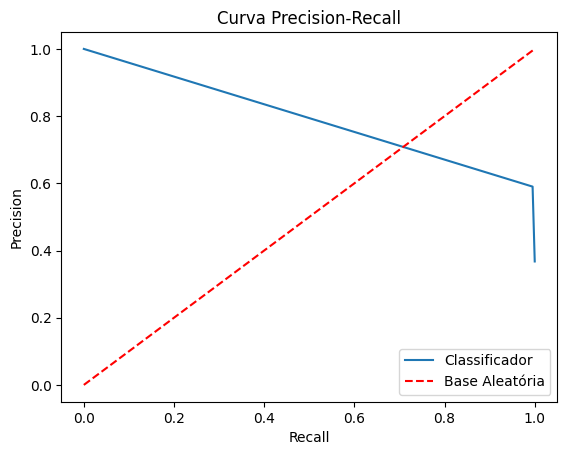

In [41]:
pg.gerar_curva_pr(y_teste, y_pred_20)

#### 3.7. Limiar Teste 95%
---


Matriz com corte em 95%:


<Axes: >

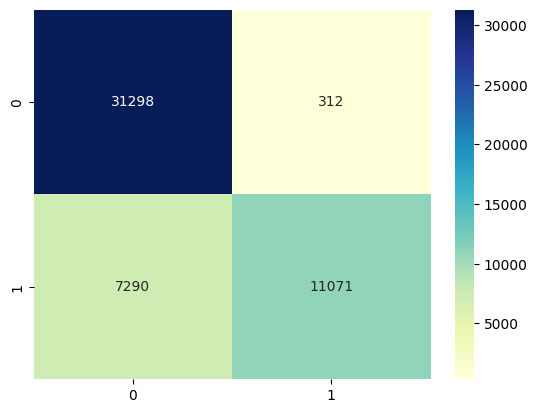

In [42]:
y_pred_95 = (y_predicao_probabilistica > 0.95).astype(int)
print("\nMatriz com corte em 95%:")
matriz_teste_5 = confusion_matrix(y_teste, y_pred_95)
sns.heatmap(matriz_teste_5, annot=True, fmt='d', cmap='YlGnBu')

In [43]:
(tn, fp), (fn, tp) = matriz_teste_5
total = (tn+fn+tp+fp)

print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 31298 casos que o modelo apontou como resultado negativo, corretamente. Representa 62.63% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 7290 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 14.59% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 11071 casos em que o modelo apontou como resultado positivo, corretamente. Representa 22.15% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 312 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 0.62% do total de predições d

In [44]:
relatorio_classificacao = classification_report(y_teste, y_pred_15)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       1.00      0.60      0.75     31610
         1.0       0.59      1.00      0.74     18361

    accuracy                           0.74     49971
   macro avg       0.79      0.80      0.74     49971
weighted avg       0.85      0.74      0.74     49971



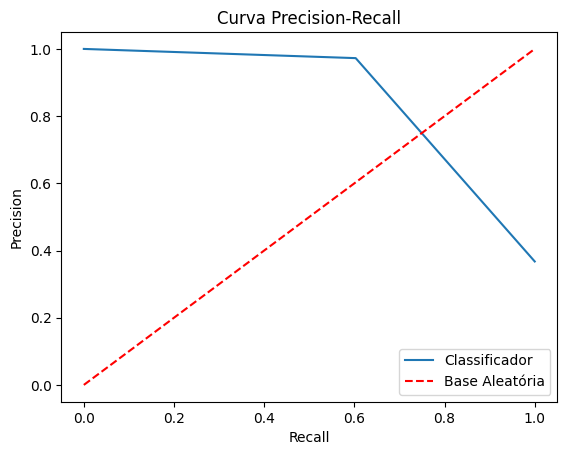

In [45]:
pg.gerar_curva_pr(y_teste, y_pred_95)

#### 3.2. Pontuação do Modelo (Acurácia Geral)
---

A `Acurácia Geral` tem como foco apontar quantas predições foram assertivas no total. Pode ser uma métrica errônea em conjuntos de dados desbalanceados. Em situações como essa, o modelo pode investir nos casos mais óbvios e deixando a resposta "pré-programada", como um chute, deixando uma acurácia alta e uma eficiência baixa. Dessa forma, esta métrica deve se analisada sempre em conjunto com as demais para garantir o sucesso do modelo.

##### 3.2.1. Criação e visualização da Pontuação do Modelo
---

In [46]:
acuracia = modelo.score(X_teste, y_teste)

In [47]:
resultado_teste = modelo.score(X_teste, y_teste)
print(f'O percentual de acurácia atual do modelo é de, aproximadamente, {(resultado_teste * 100):.2f}%.')

O percentual de acurácia atual do modelo é de, aproximadamente, 82.32%.


#### 3.3. Relatório de Classificação
---

O `Relatório de Classificação` apresenta métricas de desempenho que mostram o quanto o modelo acerta, utilizando as noções da `Matriz de Confusão` como TN, FN, TP, FP.

1. Precision (Precisão): tem como foco evitar Alarmes Falsos (Falsos Positivos). Uma precisão alta significa que o modelo é cauteloso ao rotular algo como positivo

<div style="text-align: center;">
  <img src="../../imagens/formula_precisao.png" width="400">
</div>

2. Recall (Revocação): tem como foco evitar omissões do modelo. Um recall alto significa que o modelo consegue percorrer por quase todos os casos importantes, mesmo que arrisque alguns alarmes falsos, mas evite falsos negativos.

<div style="text-align: center;">
  <img src="../../imagens/formula_recall.png" width="400">
</div>

3. F1-Score (Valor F1): É a média harmônica entre Precision e Recall. Boa métrica para perceber quando se tem classes desbalanceadas e precisa de um único número que resuma a eficiência da predição.

<div style="text-align: center;">
  <img src="../../imagens/formula_f1score.png" width="400">
</div>

##### 3.3.1. Criação e visualização do Relatório de Classificação
---

In [48]:
relatorio_classificacao = classification_report(y_teste, y_predicao_binaria)

In [49]:
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.95      0.76      0.85     31610
         1.0       0.69      0.93      0.79     18361

    accuracy                           0.82     49971
   macro avg       0.82      0.84      0.82     49971
weighted avg       0.85      0.82      0.83     49971



##### 3.3.2. Extração dos dados do Relatório de Classificação
---

Para a extração dos dados do Relatório de Classificação, deve-se transformar suas saídas em dicionários, à partir do parâmetro `output_dict`.  

In [50]:
dict_relatorio_classificacao = classification_report(y_teste, y_predicao_binaria, output_dict=True)

In [51]:
print(dict_relatorio_classificacao.keys())

dict_keys(['0.0', '1.0', 'accuracy', 'macro avg', 'weighted avg'])


In [52]:
precision_0 = dict_relatorio_classificacao['0.0']['precision']
precision_1 = dict_relatorio_classificacao['1.0']['precision']

recall_0 = dict_relatorio_classificacao['0.0']['recall']
recall_1 = dict_relatorio_classificacao['1.0']['recall']

f1_score_0 = dict_relatorio_classificacao['0.0']['f1-score']
f1_score_1 = dict_relatorio_classificacao['1.0']['f1-score']

support_0 = dict_relatorio_classificacao['0.0']['support']
support_1 = dict_relatorio_classificacao['1.0']['support']
support = support_0 + support_1

macro_avg_precision = dict_relatorio_classificacao['macro avg']['precision']
weighted_avg_precision = dict_relatorio_classificacao['weighted avg']['precision']

macro_avg_recall = dict_relatorio_classificacao['macro avg']['recall']
weighted_avg_recall = dict_relatorio_classificacao['weighted avg']['recall']

macro_avg_f1 = dict_relatorio_classificacao['macro avg']['f1-score']
weighted_avg_f1 = dict_relatorio_classificacao['weighted avg']['f1-score']

##### 3.3.3. Análise do Relatório de Classificação a partir de seus dados
---

In [53]:
print('Análises do Relatório de Classificação:')
print('\nCasos onde não foram detectadas ameaças (0):')
print(f'\n - O total de casos é de {support_0}:')
print(f'\n - Precision é igual a, aproximadamente, {precision_0:.2f}. Isto corresponde a, aproximadamente, {(support_0 * precision_0):.2f} predições de testes.')
print(f'\n - Recall é igual a, aproximadamente, {recall_0:.2f}. Isto corresponde a, aproximadamente, {(support_0 * recall_0):.2f} predições de testes.')
print(f'\n - F1-Score é igual a, aproximadamente, {f1_score_0:.2f}. Isto corresponde a, aproximadamente, {(support_0 * f1_score_0):.2f} predições de testes.')

print('\n\nCasos onde foram detectadas ameaças(1):')
print(f'\n - O total de casos é de {support_1}:')
print(f'\n - Precision é igual a, aproximadamente, {precision_1:.2f}. Isto corresponde a, aproximadamente, {(support_1 * precision_1):.2f} predições de testes.')
print(f'\n - Recall é igual a, aproximadamente, {recall_1:.2f}. Isto corresponde a, aproximadamente, {(support_1 * recall_1):.2f} predições de testes.')
print(f'\n - F1-Score é igual a, aproximadamente, {f1_score_1:.2f}. Isto corresponde a, aproximadamente, {(support_1 * f1_score_1):.2f} predições de testes.')

print('\n\nAs médias foram:')
print('\n Média Aritmética (Macro AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: aproximadamente {macro_avg_precision:.2f}. Isto corresponde a, aproximadamente, {(support * macro_avg_precision):.2f}.')
print(f'\n - Recall: aproximadamente {macro_avg_recall:.2f}. Isto corresponde a, aproximadamente, {(support * macro_avg_recall):.2f}.')
print(f'\n - F1-Score: aproximadamente {macro_avg_f1:.2f}. Isto corresponde a, aproximadamente, {(support * macro_avg_f1):.2f}.')

print('\n\n Média Ponderada (Weighted AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: aproximadamente {weighted_avg_precision:.2f}. Isto corresponde a, aproximadamente, {(support * weighted_avg_precision):.2f}.')
print(f'\n - Recall: aproximadamente {weighted_avg_recall:.2f}. Isto corresponde a, aproximadamente, {(support * weighted_avg_recall):.2f}.')
print(f'\n - F1-Score: aproximadamente {weighted_avg_f1:.2f}. Isto corresponde a, aproximadamente, {(support * weighted_avg_f1):.2f}.\n')

Análises do Relatório de Classificação:

Casos onde não foram detectadas ameaças (0):

 - O total de casos é de 31610.0:

 - Precision é igual a, aproximadamente, 0.95. Isto corresponde a, aproximadamente, 29914.95 predições de testes.

 - Recall é igual a, aproximadamente, 0.76. Isto corresponde a, aproximadamente, 24143.00 predições de testes.

 - F1-Score é igual a, aproximadamente, 0.85. Isto corresponde a, aproximadamente, 26720.83 predições de testes.


Casos onde foram detectadas ameaças(1):

 - O total de casos é de 18361.0:

 - Precision é igual a, aproximadamente, 0.69. Isto corresponde a, aproximadamente, 12755.87 predições de testes.

 - Recall é igual a, aproximadamente, 0.93. Isto corresponde a, aproximadamente, 16993.00 predições de testes.

 - F1-Score é igual a, aproximadamente, 0.79. Isto corresponde a, aproximadamente, 14572.69 predições de testes.


As médias foram:

 Média Aritmética (Macro AVG):

 - O total de casos é 49971.0

 - Precision: aproximadamente 0.82. I

#### 3.4. Curva ROC AUC
---

A curva `ROC (Receiver Operating Characteristic)` e a métrica `AUC (Area Under the Curve)` são ferramentas muito importantes para a medição de desempenho de `Modelos de Classificação`. Ela mede a capacidade do modelo em distinguir as classes: quanto maior o AUC, melhor o modelo é em prever 0 como 0 e 1 como 1, mas ainda assim, é melhor para medir o desempenho das probabilidades com o método `predict_proba` do que com o `predict`.

1. Curva ROC: É um gráfico que ilustra o equilíbrio entre a Taxa de Verdadeiros Positivos (Sensibilidade) e a Taxa de Falsos Positivos (1 - Especificidade) para todos os limiares (thresholds) possíveis de classificação.

2. AUC (Área sob a Curva): É um valor numérico que varia de 0 a 1 e resume a performance do modelo:

   - 1.0: Classificador perfeito.

   - 0.5: Classificador aleatório (equivalente ao acaso).

   -  Acima de 0.7: Geralmente indica um bom poder preditivo.
  
3. Os eixos são os seguintes:

    - Eixo Y (Taxa de Verdadeiro Positivo / Sensibilidade): Representa o Recall. Quanto mais alto, melhor para o modelo, já que este será mais abrangente ao processar os dados, conseguindo capturar um maior número de ameaças.

    - Eixo X (Taxa de Falso Positivo): É o custo do erro. Ele mostra, em relação a todos os casos normais, quantos o modelo marcou erradamente como ameaça. Quanto mais baixo (à esquerda), melhor.
  
4. A "Linha de Sorte" (Pontilhada):

    - A linha diagonal representa um modelo que decide com aleatoriedade.

    - Se curva estiver próximo a essa linha diagonal, ele será pouco útil.
  
    - Se estiver acima, mais distante, terá uma utilidade maior, por não depender tanto de aleatoriedade.
  
5. O Ponto Ideal:

    O objetivo do modelo é chegar o mais próximo possível do canto superior esquerdo (coordenada 0.0 no X e 1.0 no Y). 

##### 3.4.1. Plot do gráfico da Curva ROC AUC
---

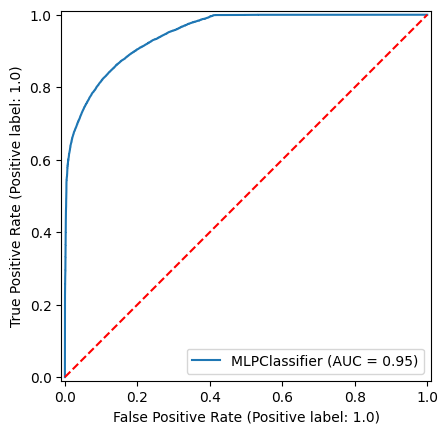

In [54]:
curva = RocCurveDisplay.from_estimator(modelo, X_teste, y_teste)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()

##### 3.4.2. Extração do valor de AUC
---

In [55]:
auc_valor = curva.roc_auc
print(f'O valor de AUC do modelo é {auc_valor}.')

O valor de AUC do modelo é 0.9485244728292835.


##### 3.4.3. Análise do gráfico
---

### 4. Persisitindo o Modelo -> Ver o Pipeline do SKLEARN
---

In [56]:
# joblib.dump(modelo, '../modelos_persistentes/mlp/binario/mlp_binario_4c.pkl')